# Fraud Detection Case - Intern Data Scientist Brazil
**Author:** Davi de Souza Santos

This notebook develops a supervised fraud detection solution using labeled 2025 transactions and scores the unlabeled January 2026 transactions. The workflow follows the case requirements and keeps validation chronological.

## Notebook structure

1. [Executive Summary](#00-executive-summary)
2. [Setup and Data Loading](#01-setup-and-data-loading)
3. [Exploratory Data Analysis](#02-exploratory-data-analysis)
4. [Feature Engineering](#03-feature-engineering)
5. [Model Development and Temporal Validation](#04-model-development-and-temporal-validation)
6. [January 2026 Scoring and Deliverables](#05-january-2026-scoring-and-deliverables)

# 00. Summary

## 00.1 Goals

### 00.1.1 Business problem

The Fraud Prevention team of a financial institution has a consolidated process to review suspicious transactions. As the volume of operations grows, this process, which is largely manual, has become inefficient and hard to scale. This creates a double challenge:

- **Financial loss:** fraudulent transactions that are not detected in time.
- **Customer experience:** legitimate customers whose transactions are wrongly blocked.

The two errors have different costs. A missed fraud (false negative) is a direct loss, while a blocked legitimate transaction (false positive) hurts the customer relationship. Any solution has to balance both, and fraud is a rare event, so a model that simply labels everything as "not fraud" would look accurate while being useless.

The institution wants a Machine Learning solution that automates the identification of potentially fraudulent transactions, using a historical dataset in which part of the transactions were already labeled as fraud.

### 00.1.2 Defined Goals

**Main goal:** build a predictive model that classifies each transaction as *fraudulent* or *non-fraudulent*, and use it to classify the January 2026 transactions, which have no label.

**Specific goals:**

1. **Explore the data** (EDA) to understand what separates fraud from legitimate transactions, check data quality, and verify that January 2026 behaves like the 2025 history used for training.
2. **Engineer features** that capture the patterns found in the EDA, using only information available at the moment of the transaction.
3. **Train and compare models**, starting from a simple benchmark, and keep the simplest model that performs well and can be explained.
4. **Evaluate with metrics suited to rare events** (precision, recall, F1 and PR-AUC) on a temporal validation, where the model is trained on earlier periods and tested on later ones, as it would be used in practice.
5. **Choose and justify a decision threshold** in business terms, balancing undetected fraud against blocked legitimate customers.
6. **Deliver the results:** the January 2026 base with the classification and a presentation with the method, the results.

**Scope and limits:** the January 2026 base has no labels, so its classification cannot be measured directly. Performance is estimated on held-out periods of 2025, and the conclusions about January rely on the assumption that its behavior is similar to the training data, which is checked in the EDA.


## 00.2 Results
### 00.2.1 Conclusions and Recommendations
### 00.2.2 EDA
#### 00.2.2.1 Questions and their inferences
#### 00.2.2.2 What the data cannot answer
### 00.2.3 Feature Engineering
#### 00.2.3.1 Features chosen and why
#### 00.2.3.2 Validation Strategy
### 00.2.4 Model
#### 00.2.4.1 Machine Learning model chosen and why
#### 00.2.4.2 Results
#### 00.2.4.3 Threshold

## 00.3 Limitations

# 01. Setup and Data Loading

In [2]:
from pathlib import Path
 
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2
from sklearn.metrics import average_precision_score, mutual_info_score, roc_auc_score
from sklearn.tree import DecisionTreeClassifier, export_text

pd.set_option("display.max_columns", 50)

# Data paths
# 1. Training set
DATA_2025 = Path("data/transacoes_historico_2025.csv")
# 2. Scoring set
DATA_2026 = Path('data/transacoes_jan2026.csv')
# 3. Resulting figures path
FIG_DIR = Path("outputs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Target definition
TARGET = "flag_fraude"

def save_fig(name: str) -> None:
    """Save the current figure so it can be reused in the presentation."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

In [3]:
df = pd.read_csv(DATA_2025, parse_dates=["datahora_transacao"])
df_jan =pd.read_csv(DATA_2026, parse_dates=["datahora_transacao"])

print("2025 (train):", df.shape)
print("Jan 2026 (test):", df_jan.shape)
df.head()

2025 (train): (523525, 15)
Jan 2026 (test): (44451, 14)


,datahora_transacao,nome_estabelecimento,tipo_estabelecimento,valor_transacao,nome_cliente,cidade,flag_fraude,device_type,is_new_device,temperatura_celsius,codigo_postal,score_interno,turno,valor_categoria,cidade_regiao
0,2025-01-01 00:00:00,Pharmacy Z,Pharmacy,9.12,Cliente_16621,Recife,False,desktop,False,31.5,72519-282,562,madrugada,baixo,Nordeste
1,2025-01-01 00:01:00,Supermarket A,Supermarket,37.74,Cliente_12596,Recife,False,mobile,False,28.1,43549-179,461,madrugada,medio,Nordeste
2,2025-01-01 00:02:00,Restaurant Y,Food & Beverage,30.94,Cliente_10474,Salvador,False,mobile,True,29.1,68582-277,577,madrugada,medio,Nordeste
3,2025-01-01 00:03:00,Gas Station,Fuel,41.72,Cliente_20661,Salvador,False,mobile,True,28.6,21497-208,666,madrugada,medio,Nordeste
4,2025-01-01 00:04:00,Online Shop 2,E-commerce,13.85,Cliente_4018,Rio de Janeiro,False,mobile,False,30.2,50814-648,892,madrugada,baixo,Sudeste


#### Inference 01.1
> January has the same features as 2025 history, except for `flag_fraud`, our target.

# 02. Exploratory Data Analysis

Goals of this step:

1. Understand the structure and data quality.
2. Understand the target (`flag_fraude`) in the historic 2025 database.
3. Find which variables separate fraud from non-fraud.
4. Check which columns are redundant or useless.
5. Check wheter January 2026 (the testing set) looks like the training data.

## 02.1 Questions answered by EDA

#### Question 02.1.1: Is the fraud rate and the fraud pattern stable over the year?

#### Questionn 02.1.2: Which interactions matter beyond single variables?

#### Question 02.1.3: Which variables carry information, ranked quantitatively?

#### Question 02.1.4: How far can a very simple rule-based benchmark go?
> Show the results that the simple benchmark made

#### Question 02.1.5: What is the financial profile of fraud?

#### Question 02.1.6: Does customer history help?
> Features like velocity, new city, new merchant, repeat victims, help to detect a fraud?

#### Question 02.1.7: Are frauds clustered in time at the same merchant (bursts)?

#### Question 02.1.8: Does January 2026 look like 2025 history?

## 02.2 Structure and data quality
Basic quality checks

In [4]:
print("Columns only in train :", set(df.columns) - set(df_jan.columns))
print("Columns only in Jan 26:", set(df_jan.columns) - set(df.columns))
print("\nMissing values (train):", int(df.isna().sum().sum()))
print("Duplicated rows (train):", int(df.duplicated().sum()))
print("Duplicated rows (Jan 26):", int(df_jan.duplicated().sum()))
print("\nTime coverage (train):", df.datahora_transacao.min(), "->", df.datahora_transacao.max())
print("Time coverage (Jan 26):", df_jan.datahora_transacao.min(), "->", df_jan.datahora_transacao.max())
df.dtypes


Columns only in train : {'flag_fraude'}
Columns only in Jan 26: set()

Missing values (train): 0
Duplicated rows (train): 0
Duplicated rows (Jan 26): 0

Time coverage (train): 2025-01-01 00:00:00 -> 2025-12-31 23:59:00
Time coverage (Jan 26): 2026-01-01 00:00:00 -> 2026-01-31 23:58:00


datahora_transacao      datetime64[us]
nome_estabelecimento               str
tipo_estabelecimento               str
valor_transacao                float64
nome_cliente                       str
cidade                             str
flag_fraude                       bool
device_type                        str
is_new_device                     bool
temperatura_celsius            float64
codigo_postal                      str
score_interno                    int64
turno                              str
valor_categoria                    str
cidade_regiao                      str
dtype: object

#### Inference 02.2.1
> The data has no duplicates or missing values for both training and scoring sets. It's already sorted by timestamp apparently, but we will ensure it's sorted by timestamp below.

Sort sets by time

In [5]:
df = df.sort_values("datahora_transacao").reset_index(drop=True)
df_jan = df_jan.sort_values("datahora_transacao").reset_index(drop=True)
 
for d in (df, df_jan):
    d["month"] = d.datahora_transacao.dt.to_period("M")
    d["hour"] = d.datahora_transacao.dt.hour
    d["dayofweek"] = d.datahora_transacao.dt.day_of_week
    d["day"] = d.datahora_transacao.dt.day
    d["date"] = d.datahora_transacao.dt.normalize()
 
print("2025:", df.shape, "|", df.datahora_transacao.min(), "->", df.datahora_transacao.max())
print("Jan 2026:", df_jan.shape)


2025: (523525, 20) | 2025-01-01 00:00:00 -> 2025-12-31 23:59:00
Jan 2026: (44451, 19)


## 02.3 Target: class balance

In [6]:
counts = df[TARGET].value_counts()
rate = df[TARGET].mean()
print(counts.to_string())
print(f"\nFraud rate: {rate:.2%}  (about 1 fraud every {1 / rate:.0f} transactions)")
print("Accuracy of a model that always predicts 'not fraud':", f"{1 - rate:.2%}")


flag_fraude
False    503040
True      20485

Fraud rate: 3.91%  (about 1 fraud every 26 transactions)
Accuracy of a model that always predicts 'not fraud': 96.09%


#### Inference 02.3.1
> ~96% of the transactions are non-fraudulent. A model that always predicts 'not fraud' have 96% accuracy, making it an useless metric.

### 02.3.1 Fraud rate over time

Monthly overview

         transactions  frauds  fraud_rate  avg_amount  new_device_share
month                                                                  
2025-01         44463    1659      0.0373     43.9968            0.1642
2025-02         40162    1484      0.0370     43.8124            0.1630
2025-03         44473    1691      0.0380     44.0750            0.1640
2025-04         43028    1644      0.0382     44.4821            0.1650
2025-05         44464    1643      0.0370     44.1028            0.1650
2025-06         43022    1643      0.0382     44.1399            0.1667
2025-07         44464    1773      0.0399     43.6557            0.1679
2025-08         44448    1651      0.0371     43.9863            0.1654
2025-09         43042    1613      0.0375     43.5488            0.1642
2025-10         44468    1693      0.0381     43.7505            0.1647
2025-11         43040    1580      0.0367     43.4270            0.1671
2025-12         44451    2411      0.0542     44.5557           

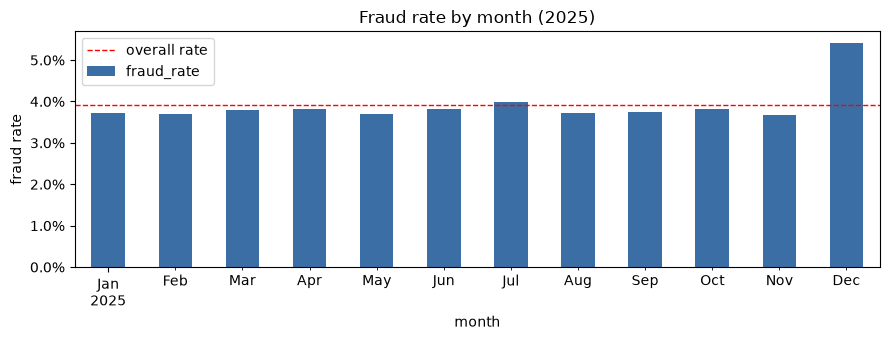

In [7]:
monthly = df.groupby("month").agg(
    transactions=(TARGET, "size"),
    frauds=(TARGET, "sum"),
    fraud_rate=(TARGET, "mean"),
    avg_amount=("valor_transacao", "mean"),
    new_device_share=("is_new_device", "mean"),
)
print(monthly.round(4).to_string())
 
ax = monthly["fraud_rate"].plot.bar(figsize=(9, 3.5), color="#3b6ea5")
ax.axhline(df[TARGET].mean(), color="red", ls="--", lw=1, label="overall rate")
ax.set_ylabel("fraud rate")
ax.set_title("Fraud rate by month (2025)")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.1%}")
ax.legend()
save_fig("monthly_fraud_rate")

#### Inference 02.3.2
> The transactions volume by month is stable in 2025 history (the average amount has a low deviation between months), so does the fraud rate, except by December, where the fraud rate is above 5%, a ~25% increase relative to the average rate. That happens while the transactions amount stay quite the same.

Weekly trend and abnormal days

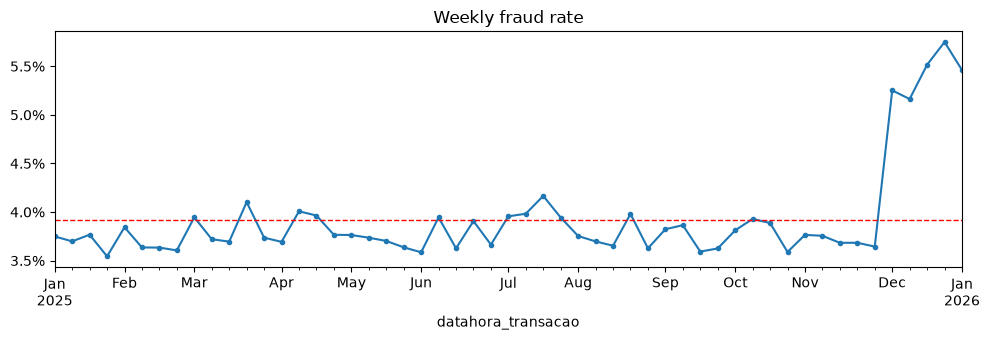

In [8]:
weekly = df.set_index("datahora_transacao")[TARGET].resample("W").mean()
ax = weekly.plot(figsize=(10, 3.5), marker="o", ms=3)
ax.axhline(df[TARGET].mean(), color="red", ls="--", lw=1)
ax.set_title("Weekly fraud rate")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.1%}")
save_fig("weekly_fraud_rate")


#### Inference 02.3.3
> The weekly trend show that fraud rate in December is truly significantly higher. Apparently, there is no monthly seasonality worth a study in the history, but transactions by december appears like a candidate for model prediction. The problem is: we are predicting frauds in January 2026, in which December increased rate has no effect.

Days whose fraud count is far from the overall rate (binomial z-score)

In [9]:
p = df[TARGET].mean()
daily = df.groupby("date")[TARGET].agg(n="size", frauds="sum")
daily["z"] = (daily.frauds - daily.n * p) / np.sqrt(daily.n * p * (1 - p))
print("\nDays with |z| > 3 (unusual fraud counts):")
unusual = daily[daily.z.abs() > 3]
print(unusual.round(2).to_string() if len(unusual) else "none")
print("\nNumber of days analysed:", len(daily), "| expected by chance at |z|>3: ~", round(len(daily) * 0.0027, 1))


Days with |z| > 3 (unusual fraud counts):
               n  frauds     z
date                          
2025-02-20  1435      33 -3.15
2025-10-24  1429      33 -3.13
2025-12-02  1436      85  3.92
2025-12-04  1433      81  3.40
2025-12-05  1431      79  3.14
2025-12-08  1437      79  3.10
2025-12-13  1433      80  3.26
2025-12-18  1432      79  3.13
2025-12-20  1438      86  4.04
2025-12-21  1436      94  5.15
2025-12-22  1433      82  3.53
2025-12-23  1435     101  6.11
2025-12-24  1434      85  3.93
2025-12-25  1435      93  5.02
2025-12-28  1431      83  3.68
2025-12-29  1434      89  4.48

Number of days analysed: 365 | expected by chance at |z|>3: ~ 1.0


#### Inference 02.3.4
> For the 16 days showed, 14 of them are in December. The strongest deviations are in 12/23/25 and 12/25/25, pre-Christmas Eve and Christmas day. That show us that December has an unusual fraud rate, specially around Christmas and New Year.

Day of month and day of week

In [10]:
print("Fraud rate by day of month:")
print(df.groupby("day")[TARGET].mean().round(4).to_string())
print("\nFraud rate by day of week (0 = Monday):")
print(df.groupby("dayofweek")[TARGET].mean().round(4).to_string())

Fraud rate by day of month:
day
1     0.0387
2     0.0374
3     0.0385
4     0.0389
5     0.0399
6     0.0404
7     0.0394
8     0.0395
9     0.0377
10    0.0409
11    0.0384
12    0.0393
13    0.0389
14    0.0381
15    0.0382
16    0.0389
17    0.0383
18    0.0410
19    0.0386
20    0.0389
21    0.0401
22    0.0418
23    0.0398
24    0.0373
25    0.0408
26    0.0371
27    0.0381
28    0.0390
29    0.0392
30    0.0404
31    0.0399

Fraud rate by day of week (0 = Monday):
dayofweek
0    0.0405
1    0.0391
2    0.0401
3    0.0386
4    0.0376
5    0.0385
6    0.0395


#### Inference 02.3.5
> Consistent rates across all days, no unusual numbers. Day of month/week has a weak value as predictor.

Special dates

In [11]:
special = {
    "New Year's Day": ("2025-01-01", "2025-01-01"),
    "Carnival": ("2025-03-01", "2025-03-05"),
    "Black Friday": ("2025-11-28", "2025-11-28"),
    "Christmas": ("2025-12-24", "2025-12-25"),
    "New Year's Eve": ("2025-12-31", "2025-12-31"),
}
rows = []
for name, (a, b) in special.items():
    m = (df.date >= a) & (df.date <= b)
    if m.sum():
        rows.append({"event": name, "n": int(m.sum()), "fraud_rate": df.loc[m, TARGET].mean(),
                     "avg_amount": df.loc[m, "valor_transacao"].mean()})
rows.append({"event": "all other days", "n": int(len(df)), "fraud_rate": p, "avg_amount": df.valor_transacao.mean()})
print(pd.DataFrame(rows).round(4).to_string(index=False))


         event      n  fraud_rate  avg_amount
New Year's Day   1437      0.0404     42.6884
      Carnival   7178      0.0368     43.4200
  Black Friday   1437      0.0313     44.7343
     Christmas   2869      0.0620     43.5622
New Year's Eve   1435      0.0516     46.1425
all other days 523525      0.0391     43.9629


#### Inference 02.3.6

> Fraud rates are significantly bigger by Christmas and New Years's Eve. They would be strong predictors in an yearly predictor.

### 02.3.2 Are the key relationships stable month by month?
Hour x month heatmap

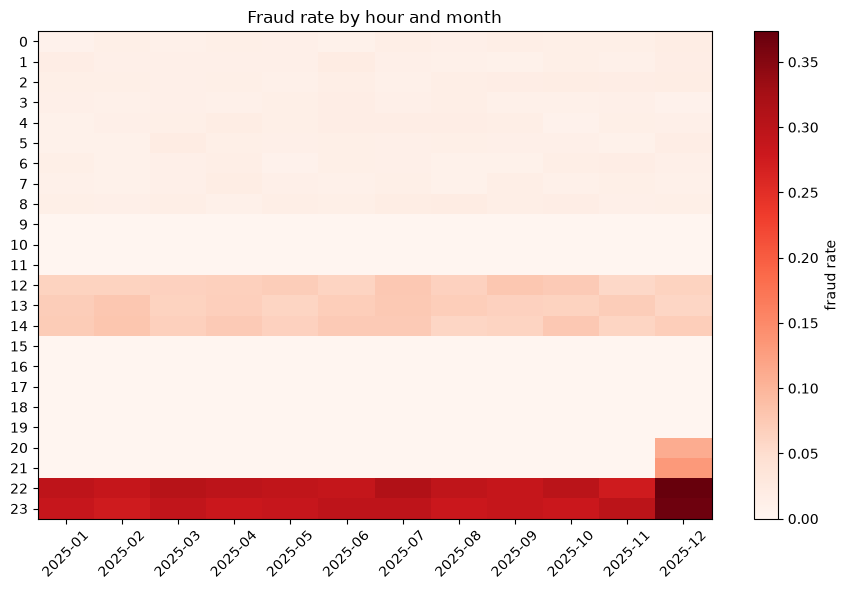

In [12]:
hm = df.pivot_table(index="hour", columns="month", values=TARGET, aggfunc="mean")
fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(hm.values, aspect="auto", cmap="Reds")
ax.set_yticks(range(len(hm.index)), hm.index)
ax.set_xticks(range(len(hm.columns)), [str(c) for c in hm.columns], rotation=45)
ax.set_title("Fraud rate by hour and month")
fig.colorbar(im, label="fraud rate")
save_fig("hour_by_month_heatmap")

#### Inference 02.3.7
> Fraud rate is significantly higher by 21h30 to 00h every month, and increase by December. We also noted the pattern from 11h30 to 14h30. We can also see that the rate is a bit higher from 00 to 8h30 compared to (8h30, 11h30] and [14h30,21h30). Those intervals could add prediction value as features.

### 02.3.3 Fraud rate by categorical variable

In [13]:
def fraud_by(col: str, data: pd.DataFrame = df) -> pd.DataFrame:
    out = data.groupby(col)[TARGET].agg(n="size", frauds="sum", fraud_rate="mean")
    return out.sort_values("fraud_rate", ascending=False)
 
 
def plot_rate(col: str, data: pd.DataFrame = df, name: str | None = None) -> None:
    t = fraud_by(col, data)
    ax = t["fraud_rate"].plot.bar(figsize=(7, 3.5), color="#3b6ea5")
    ax.axhline(data[TARGET].mean(), color="red", ls="--", lw=1, label="overall rate")
    ax.set_ylabel("fraud rate")
    ax.set_title(f"Fraud rate by {col}")
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.legend()
    save_fig(name or f"fraud_rate_{col}")

Categorical variables

In [14]:
for c in ["tipo_estabelecimento", "nome_estabelecimento", "cidade", "device_type", "is_new_device", "turno"]:
    print(f"\n--- {c} ---")
    print(fraud_by(c).round(4).to_string())


--- tipo_estabelecimento ---
                           n  frauds  fraud_rate
tipo_estabelecimento                            
Fuel                   52163    3937      0.0755
Food & Beverage       104675    6939      0.0663
E-commerce            105223    3288      0.0312
Retail                104648    2623      0.0251
Supermarket           104225    2475      0.0237
Pharmacy               52591    1223      0.0233

--- nome_estabelecimento ---
                          n  frauds  fraud_rate
nome_estabelecimento                           
Gas Station           52163    3937      0.0755
Restaurant X          52163    3497      0.0670
Restaurant Y          52512    3442      0.0655
Online Shop 2         52853    1660      0.0314
Online Shop 1         52370    1628      0.0311
Electronics Store     52289    1317      0.0252
Clothing Store        52359    1306      0.0249
Supermarket A         52430    1263      0.0241
Supermarket B         51795    1212      0.0234
Pharmacy Z          

#### Inference 02.3.8
> - Gas stations and restaurants have +100% increase in fraud rate compared to other places. The transactions amount is consistent across shop names.
> - São Paulo and Rio de Janeiro rates are significantly higher than other cities. The transactions amount is consistent across cities.
> - Fraud rate is ~5% on mobile devices and below 3% on others.
> - Fraud rate is 600% higher in new devices compared to old devices transaction. Perhaps the strongest predictor.
> - Fraud rate is 10% by night, 3.5% by the afternoon and below 1.5% by other periods of the day. The transactions amount is consistent across periods.

Plots for the strongest categorical signals

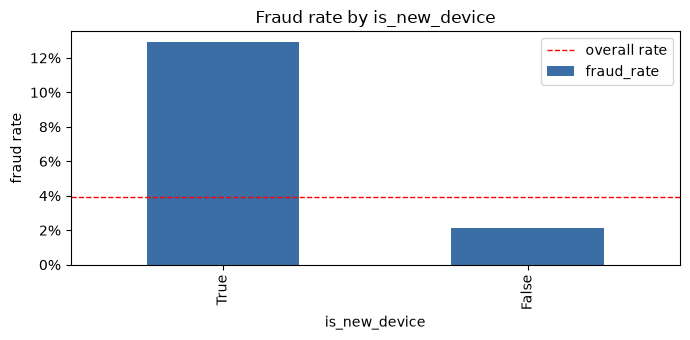

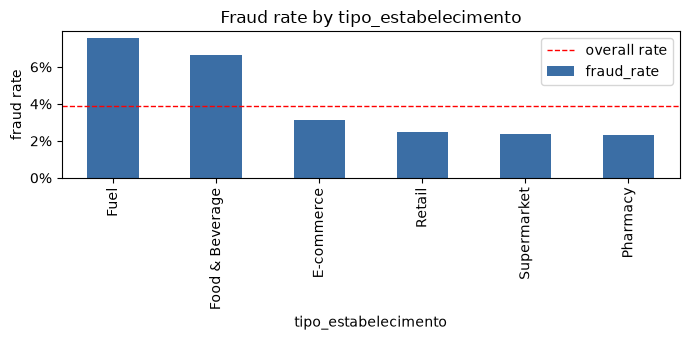

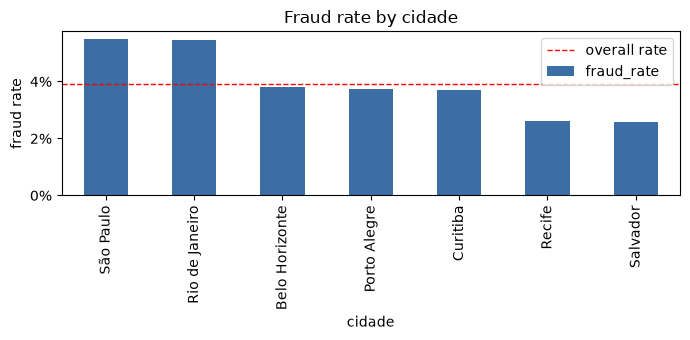

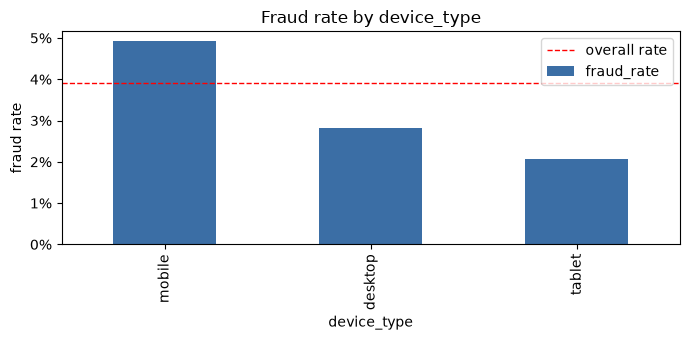

In [15]:
plot_rate("is_new_device")
plot_rate("tipo_estabelecimento")
plot_rate("cidade")
plot_rate("device_type")

#### Inference 02.3.9
> Possible strongest predictors:
> 1. `is_new_device: True`;
> 2. `tipo_estabelecimento: Fuel`;
> 3. `tipo_estabelecimento: Foods & Beverage`;
> 4. `device_type: mobile`;
> 5. `cidade: São Paulo`;
> 6. `cidade: Rio de Janeiro`;

### 02.3.4 Time of day

Fraud rate by hour

          n  frauds  fraud_rate
hour                           
0     21799     291      0.0133
1     21811     296      0.0136
2     21810     320      0.0147
3     21805     266      0.0122
4     21811     304      0.0139
5     21814     287      0.0132
6     21819     274      0.0126
7     21836     268      0.0123
8     21820     327      0.0150
9     21821       0      0.0000
10    21811       0      0.0000
11    21821       0      0.0000
12    21813    1463      0.0671
13    21806    1478      0.0678
14    21819    1508      0.0691
15    21805       0      0.0000
16    21823       0      0.0000
17    21805       0      0.0000
18    21820       0      0.0000
19    21822       0      0.0000
20    21808     203      0.0093
21    21812     243      0.0111
22    21805    6551      0.3004
23    21809    6406      0.2937


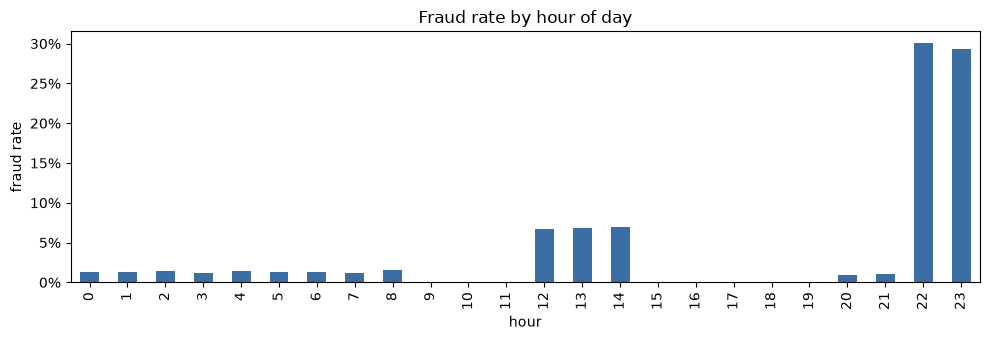


By day of week (0 = Monday):
dayofweek
0    0.0405
1    0.0391
2    0.0401
3    0.0386
4    0.0376
5    0.0385
6    0.0395


In [16]:
df["hour"] = df.datahora_transacao.dt.hour
df["dayofweek"] = df.datahora_transacao.dt.day_of_week
 
hourly = df.groupby("hour")[TARGET].agg(n="size", frauds="sum", fraud_rate="mean")
print(hourly.round(4).to_string())
 
ax = hourly["fraud_rate"].plot.bar(figsize=(10, 3.5), color="#3b6ea5")
ax.set_title("Fraud rate by hour of day")
ax.set_ylabel("fraud rate")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
save_fig("fraud_rate_hour")
 
print("\nBy day of week (0 = Monday):")
print(df.groupby("dayofweek")[TARGET].mean().round(4).to_string())


#### Inference 02.3.10
> Having no fraud by 9 to 11 and 15 to 19 may be a problem to predict frauds in those hours. Fraud rate is heterogenous across daytime.

Window of hours and new device by month

In [17]:
def hour_window(h: int) -> str:
    if h in (22, 23):
        return "22-23h"
    if 12 <= h <= 14:
        return "12-14h"
    if h <= 8:
        return "00-08h"
    return "09-11h & 15-21h"
 
 
df["hour_window"] = df.hour.map(hour_window)
print("Fraud rate by hour window and month:")
print(df.pivot_table(index="hour_window", columns="month", values=TARGET, aggfunc="mean").round(4).to_string())
print("\nFraud rate by new device and month:")
print(df.pivot_table(index="is_new_device", columns="month", values=TARGET, aggfunc="mean").round(4).to_string())

Fraud rate by hour window and month:
month            2025-01  2025-02  2025-03  2025-04  2025-05  2025-06  2025-07  2025-08  2025-09  2025-10  2025-11  2025-12
hour_window                                                                                                                
00-08h            0.0122   0.0117   0.0137   0.0144   0.0126   0.0144   0.0138   0.0138   0.0133   0.0133   0.0133   0.0142
09-11h & 15-21h   0.0000   0.0000   0.0000   0.0000   0.0000   0.0000   0.0000   0.0000   0.0000   0.0000   0.0000   0.0241
12-14h            0.0688   0.0735   0.0647   0.0696   0.0653   0.0683   0.0750   0.0643   0.0684   0.0716   0.0627   0.0643
22-23h            0.2900   0.2806   0.2974   0.2889   0.2889   0.2915   0.3038   0.2877   0.2868   0.2899   0.2866   0.3700

Fraud rate by new device and month:
month          2025-01  2025-02  2025-03  2025-04  2025-05  2025-06  2025-07  2025-08  2025-09  2025-10  2025-11  2025-12
is_new_device                                               

#### Inference 02.3.11
> Rates are consistent across all months, despite for a relevant increase in December for all categories, including the period of the day with 0% rate.

### 02.3.5 Interactions

Hour x new device

is_new_device   False   True 
hour                         
0              0.0060  0.0528
1              0.0073  0.0472
2              0.0079  0.0519
3              0.0064  0.0441
4              0.0074  0.0485
5              0.0061  0.0509
6              0.0073  0.0413
7              0.0065  0.0430
8              0.0076  0.0559
9              0.0000  0.0000
10             0.0000  0.0000
11             0.0000  0.0000
12             0.0377  0.2049
13             0.0363  0.2161
14             0.0390  0.2112
15             0.0000  0.0000
16             0.0000  0.0000
17             0.0000  0.0000
18             0.0000  0.0000
19             0.0000  0.0000
20             0.0047  0.0349
21             0.0059  0.0401
22             0.1879  0.5992
23             0.1829  0.6010


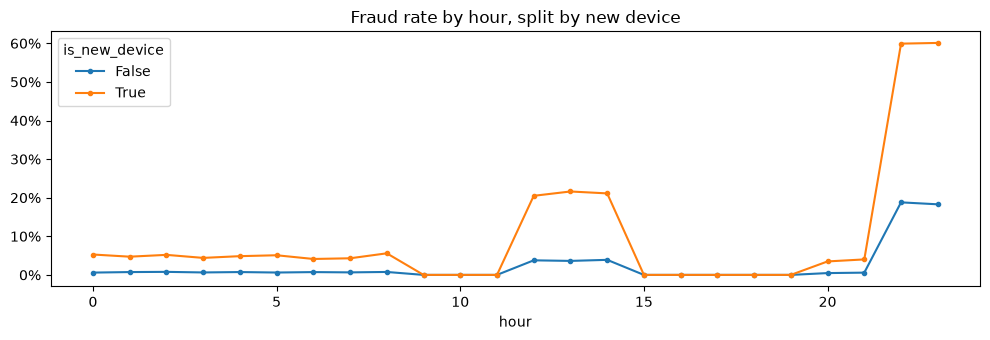

In [18]:
hd = df.pivot_table(index="hour", columns="is_new_device", values=TARGET, aggfunc="mean")
print(hd.round(4).to_string())
ax = hd.plot(figsize=(10, 3.5), marker="o", ms=3)
ax.set_title("Fraud rate by hour, split by new device")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
save_fig("hour_by_new_device")

#### Inference 02.3.12
> Combinating new device info with hour may make a strong predictor to identify frauds.

Amount x Merchant type

In [19]:
AMOUNT_EDGES = [0, 8, 12, 16, 20, 25, 31, 39, 52, 79, np.inf]  # taken from the sample deciles
df["amount_bin"] = pd.cut(df.valor_transacao, AMOUNT_EDGES)
print("Fraud rate by amount bin and merchant type:")
print(df.pivot_table(index="amount_bin", columns="tipo_estabelecimento", values=TARGET,
                     aggfunc="mean", observed=True).round(4).to_string())
print("\nFraud amount by merchant type:")
print(df[df[TARGET]].groupby("tipo_estabelecimento")["valor_transacao"].describe().round(2).to_string())

Fraud rate by amount bin and merchant type:
tipo_estabelecimento  E-commerce  Food & Beverage    Fuel  Pharmacy  Retail  Supermarket
amount_bin                                                                              
(0.0, 8.0]                0.0027           0.0052  0.0071    0.0023  0.0022       0.0019
(8.0, 12.0]               0.0130           0.0306  0.0354    0.0095  0.0107       0.0111
(12.0, 16.0]              0.0337           0.0585  0.0675    0.0163  0.0232       0.0196
(16.0, 20.0]              0.0389           0.0802  0.0983    0.0306  0.0295       0.0312
(20.0, 25.0]              0.0489           0.1008  0.1205    0.0366  0.0412       0.0371
(25.0, 31.0]              0.0522           0.1115  0.1215    0.0408  0.0446       0.0407
(31.0, 39.0]              0.0493           0.1080  0.1202    0.0394  0.0414       0.0416
(39.0, 52.0]              0.0416           0.0903  0.0943    0.0319  0.0328       0.0292
(52.0, 79.0]              0.0241           0.0512  0.0583    0.020

Hour window x merchant type

In [20]:
print("Fraud rate by hour window and merchant type:")
print(df.pivot_table(index="hour_window", columns="tipo_estabelecimento", values=TARGET, aggfunc="mean").round(4).to_string())

Fraud rate by hour window and merchant type:
tipo_estabelecimento  E-commerce  Food & Beverage    Fuel  Pharmacy  Retail  Supermarket
hour_window                                                                             
00-08h                    0.0000           0.0000  0.1356    0.0000  0.0000       0.0000
09-11h & 15-21h           0.0101           0.0000  0.0000    0.0000  0.0000       0.0000
12-14h                    0.0000           0.3402  0.0000    0.0000  0.0000       0.0000
22-23h                    0.3260           0.2837  0.2985    0.2849  0.2984       0.2854


#### Inference 02.3.13
> The pivot tables above suggests that the risky hours depend on the merchant type.

City x Device Type

In [21]:
print(df.pivot_table(index="cidade", columns="device_type", values=TARGET, aggfunc="mean").round(4).to_string())

device_type     desktop  mobile  tablet
cidade                                 
Belo Horizonte   0.0279  0.0480  0.0184
Curitiba         0.0283  0.0454  0.0201
Porto Alegre     0.0275  0.0469  0.0183
Recife           0.0197  0.0322  0.0139
Rio de Janeiro   0.0377  0.0693  0.0314
Salvador         0.0186  0.0324  0.0135
São Paulo        0.0383  0.0696  0.0290


#### Inference 02.3.14
> Frauds in SP and RJ capitals using mobile devices have a substantially higher rate among the comparisons above.

New device x Day period

In [22]:
inter = df.pivot_table(index="is_new_device", columns="turno", values=TARGET, aggfunc="mean")
print(inter[["madrugada", "manha", "tarde", "noite"]].round(4).to_string())

turno          madrugada   manha   tarde   noite
is_new_device                                   
False             0.0068  0.0036  0.0186  0.0577
True              0.0492  0.0237  0.1135  0.2917


#### Inference 02.3.15
> New device flag continues to appear as a strong predictor, specially in the night.

### 02.3.6 Transaction amount
Amount distribution by class

                count   mean    std   min    25%    50%    75%     max
flag_fraude                                                           
False        503040.0  44.50  75.79  0.50  14.03  25.11  45.43  722.90
True          20485.0  30.86  16.62  4.41  19.41  27.21  37.96  218.83

Fraud rate by amount decile:
                     n  fraud_rate
amount_decile                     
(0.499, 8.5]     52370      0.0040
(8.5, 12.36]     52378      0.0191
(12.36, 16.21]   52371      0.0367
(16.21, 20.37]   52319      0.0500
(20.37, 25.25]   52374      0.0626
(25.25, 31.27]   52357      0.0658
(31.27, 39.43]   52325      0.0642
(39.43, 52.08]   52330      0.0514
(52.08, 78.856]  52348      0.0306
(78.856, 722.9]  52353      0.0069


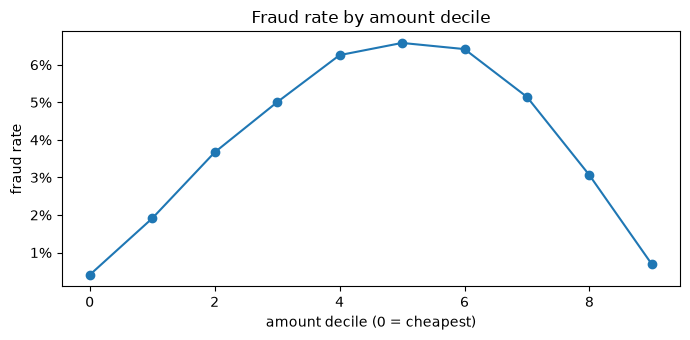

In [23]:
print(df.groupby(TARGET)["valor_transacao"].describe().round(2).to_string())
 
df["amount_decile"] = pd.qcut(df.valor_transacao, 10, duplicates="drop")
dec = df.groupby("amount_decile", observed=True)[TARGET].agg(n="size", fraud_rate="mean")
print("\nFraud rate by amount decile:")
print(dec.round(4).to_string())
 
ax = dec["fraud_rate"].reset_index(drop=True).plot(marker="o", figsize=(7, 3.5))
ax.set_xlabel("amount decile (0 = cheapest)")
ax.set_ylabel("fraud rate")
ax.set_title("Fraud rate by amount decile")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
save_fig("fraud_rate_amount_decile")

#### Inference 02.3.16
> The value amount is significantly smaller in fraudulent transactions. We can see that by max value and deviation. It may indicate that high amount transactions are non-fraudulent, but using that information for prediction inputs the risk of classifying high amount fraudulent transactions as non-fraud, which is a huge fail for the client.

### 02.3.7 No signal variables
Variables with apparently no signal: `score_interno`, `temperature`

In [24]:
df["score_bin"] = pd.cut(df.score_interno, bins=range(0, 1100, 100), include_lowest=True)
print("Fraud rate by score_interno bin:")
print(df.groupby("score_bin", observed=True)[TARGET].mean().round(4).to_string())
 
print("\ntemperatura_celsius by class:")
print(df.groupby(TARGET)["temperatura_celsius"].describe().round(2).to_string())
print("\nTemperature < 0 C:", int((df.temperatura_celsius < 0).sum()), "rows")


Fraud rate by score_interno bin:
score_bin
(-0.001, 100.0]    0.0392
(100.0, 200.0]     0.0397
(200.0, 300.0]     0.0387
(300.0, 400.0]     0.0395
(400.0, 500.0]     0.0382
(500.0, 600.0]     0.0398
(600.0, 700.0]     0.0385
(700.0, 800.0]     0.0401
(800.0, 900.0]     0.0391
(900.0, 1000.0]    0.0384

temperatura_celsius by class:
                count   mean   std   min   25%   50%   75%   max
flag_fraude                                                     
False        503040.0  24.02  6.93 -12.7  19.5  25.2  29.2  46.1
True          20485.0  23.70  6.80  -4.2  19.3  24.6  28.8  41.9

Temperature < 0 C: 637 rows


#### Inference 02.3.17
> The rate is consistent across score intervals, making this feature a weak predictor. For the brazilian cities, having 637 rows with negative temperature is a bit strange.

## 02.4 Redundant columns
Derived columns check

In [25]:
print("valor_categoria vs amount thresholds:")
print(df.groupby("valor_categoria")["valor_transacao"].agg(["min", "max"]).to_string())
 
print("\ncidade -> cidade_regiao is one-to-one?",
      df.groupby("cidade")["cidade_regiao"].nunique().max() == 1)
 
print("\nturno vs hour ranges:")
print(df.groupby("turno")["hour"].agg(["min", "max"]).to_string())
 
print("\ncodigo_postal unique values:", df.codigo_postal.nunique(), "of", len(df), "rows")


valor_categoria vs amount thresholds:
                    min    max
valor_categoria               
alto             100.01  722.9
baixo              0.50   30.0
medio             30.01  100.0

cidade -> cidade_regiao is one-to-one? True

turno vs hour ranges:
           min  max
turno              
madrugada    0    5
manha        6   11
noite       18   23
tarde       12   17

codigo_postal unique values: 521905 of 523525 rows


#### Inference 02.4.1
> - `valor_categoria` may be a good categorical value as an amout threshold, but its value to a predictive model should be questionated.
> - `cidade_regiao` is redundant to `cidade`.
> - `turno` separates daytime across intervals.
> - Approximatedly, every `codigo_postal` is unique, making this column a weak feature. 

## 02.5 Customer level

In [26]:
per_client = df.groupby("nome_cliente").agg(n_tx=(TARGET, "size"), n_fraud=(TARGET, "sum"))
print("Customers:", len(per_client))
print("Transactions per customer:\n", per_client.n_tx.describe().round(2).to_string())
print("\nCustomers with >= 1 fraud:", int((per_client.n_fraud >= 1).sum()))
print("Customers with >= 2 frauds:", int((per_client.n_fraud >= 2).sum()))

Customers: 26214
Transactions per customer:
 count    26214.00
mean        19.97
std          4.46
min          5.00
25%         17.00
50%         20.00
75%         23.00
max         44.00

Customers with >= 1 fraud: 14212
Customers with >= 2 frauds: 4826


#### Inference 02.5.1
> Mean and median are about 20 transactions by customer, making this stat very consistent. 1 or more of those 20 transactions appear to be a fraud for more than 50% of the customers, and below 20% of them have experienced 2 or more frauds.

## 02.6 Training history versus January 2026

Drift check on categorical shares

In [27]:
df_jan["hour"] = df_jan.datahora_transacao.dt.hour
 
 
def share_diff(col: str) -> pd.DataFrame:
    a = df[col].value_counts(normalize=True).rename("train_2025")
    b = df_jan[col].value_counts(normalize=True).rename("jan_2026")
    out = pd.concat([a, b], axis=1).fillna(0)
    out["abs_diff"] = (out.train_2025 - out.jan_2026).abs()
    return out.round(4)
 
 
for c in ["tipo_estabelecimento", "cidade", "device_type", "is_new_device", "turno"]:
    print(f"\n--- {c} ---")
    print(share_diff(c).to_string())


--- tipo_estabelecimento ---
                      train_2025  jan_2026  abs_diff
tipo_estabelecimento                                
E-commerce                0.2010    0.2011    0.0002
Food & Beverage           0.1999    0.1995    0.0005
Retail                    0.1999    0.1987    0.0012
Supermarket               0.1991    0.2011    0.0021
Pharmacy                  0.1005    0.1006    0.0001
Fuel                      0.0996    0.0990    0.0007

--- cidade ---
                train_2025  jan_2026  abs_diff
cidade                                        
Curitiba            0.1435    0.1450    0.0015
Rio de Janeiro      0.1432    0.1425    0.0006
Salvador            0.1430    0.1440    0.0010
Porto Alegre        0.1430    0.1431    0.0001
São Paulo           0.1426    0.1405    0.0021
Recife              0.1424    0.1434    0.0010
Belo Horizonte      0.1424    0.1414    0.0009

--- device_type ---
             train_2025  jan_2026  abs_diff
device_type                               

#### Inference 02.6.1
> Every categorical variable have consistent values comparing both sets. 

Drift check on numeric variables

In [28]:
q = [0.1, 0.5, 0.9, 0.99]
num = pd.concat(
    {
        "train_2025": df["valor_transacao"].quantile(q),
        "jan_2026": df_jan["valor_transacao"].quantile(q),
    },
    axis=1,
)
print("valor_transacao quantiles:")
print(num.round(2).to_string())

valor_transacao quantiles:
      train_2025  jan_2026
0.10        8.50      8.51
0.50       25.25     25.17
0.90       78.86     79.12
0.99      491.62    495.58


#### Inference 02.6.2
> Transaction amout percentiles consistent in both sets. The sets are very similar.

## 02.7 Which variables carry information?

Mutual information ranking

In [29]:
feats = pd.DataFrame({
    "hour": df.hour,
    "is_new_device": df.is_new_device.astype(int),
    "amount_bin": pd.qcut(df.valor_transacao, 20, duplicates="drop").cat.codes,
    "tipo_estabelecimento": df.tipo_estabelecimento,
    "nome_estabelecimento": df.nome_estabelecimento,
    "cidade": df.cidade,
    "device_type": df.device_type,
    "dayofweek": df.dayofweek,
    "month": df.month.astype(str),
    "score_interno_bin": pd.qcut(df.score_interno, 20, duplicates="drop").cat.codes,
    "temperatura_bin": pd.qcut(df.temperatura_celsius, 20, duplicates="drop").cat.codes,
})
y = df[TARGET].astype(int)
mi = pd.Series({c: mutual_info_score(feats[c], y) / np.log(2) for c in feats})  # bits
print("Mutual information with the target (bits), higher = more informative:")
print(mi.sort_values(ascending=False).round(5).to_string())


Mutual information with the target (bits), higher = more informative:
hour                    0.07505
is_new_device           0.02244
amount_bin              0.01221
nome_estabelecimento    0.00710
tipo_estabelecimento    0.00710
device_type             0.00263
cidade                  0.00231
month                   0.00038
temperatura_bin         0.00023
score_interno_bin       0.00002
dayofweek               0.00002


#### Inference 02.7.1
> Hour and new device flag appear to be our strongest predictors.

Shallow decision tree to discover rules and interactions

In [30]:
X = pd.get_dummies(
    pd.DataFrame({
        "hour": df.hour,
        "is_new_device": df.is_new_device.astype(int),
        "amount": df.valor_transacao,
        "tipo": df.tipo_estabelecimento,
        "cidade": df.cidade,
        "device": df.device_type,
    }),
    columns=["tipo", "cidade", "device"],
)
tree = DecisionTreeClassifier(max_depth=4, min_samples_leaf=200, class_weight="balanced", random_state=42)
tree.fit(X, y)
print("Note: the weights are class-balanced, so the valuable infos are splits and the predicted class, not the raw counts.\n")
print(export_text(tree, feature_names=list(X.columns), show_weights=True))

Note: the weights are class-balanced, so the valuable infos are splits and the predicted class, not the raw counts.

|--- hour <= 21.50
|   |--- is_new_device <= 0.50
|   |   |--- tipo_Food & Beverage <= 0.50
|   |   |   |--- tipo_Fuel <= 0.50
|   |   |   |   |--- weights: [148397.13, 2491.76] class: 0
|   |   |   |--- tipo_Fuel >  0.50
|   |   |   |   |--- weights: [19974.06, 14694.99] class: 0
|   |   |--- tipo_Food & Beverage >  0.50
|   |   |   |--- hour <= 11.50
|   |   |   |   |--- weights: [23285.64, 0.00] class: 0
|   |   |   |--- hour >  11.50
|   |   |   |   |--- weights: [17246.85, 25978.19] class: 1
|   |--- is_new_device >  0.50
|   |   |--- tipo_Food & Beverage <= 0.50
|   |   |   |--- tipo_Fuel <= 0.50
|   |   |   |   |--- weights: [26325.07, 3207.34] class: 0
|   |   |   |--- tipo_Fuel >  0.50
|   |   |   |   |--- weights: [3526.49, 18950.15] class: 1
|   |   |--- tipo_Food & Beverage >  0.50
|   |   |   |--- hour <= 11.50
|   |   |   |   |--- weights: [4043.73, 0.00] c

## 02.8 Simple rule based benchmark (and the temporal split)
A lookup table of fraud rates, fit on the first 70% of the period and evaluated on the last 30%.
Any machine learning model should beat this benchmark to be worth its complexity.

Temporal split and lookup benchmark

In [31]:
cut = df.datahora_transacao.quantile(0.7)
train, test = df[df.datahora_transacao <= cut], df[df.datahora_transacao > cut]
print(f"Train: {len(train):,} rows up to {cut} | fraud rate {train[TARGET].mean():.2%}")
print(f"Test : {len(test):,} rows after that | fraud rate {test[TARGET].mean():.2%}")
print(f"Random-score PR-AUC would be about {test[TARGET].mean():.4f}\n")
 
 
def lookup_score(keys: list[str], m: float = 20.0) -> np.ndarray:
    """Smoothed fraud rate of each key combination, estimated on train."""
    g = train.groupby(keys)[TARGET].agg(["sum", "count"])
    g["rate"] = (g["sum"] + m * train[TARGET].mean()) / (g["count"] + m)
    return test.join(g["rate"], on=keys)["rate"].fillna(train[TARGET].mean()).values
 
 
key_sets = [
    ["hour"],
    ["is_new_device"],
    ["hour", "is_new_device"],
    ["hour", "is_new_device", "tipo_estabelecimento"],
    ["hour", "is_new_device", "tipo_estabelecimento", "amount_bin"],
]
res = []
for ks in key_sets:
    s = lookup_score(ks)
    res.append({"keys": " + ".join(ks), "PR-AUC": average_precision_score(test[TARGET], s),
                "ROC-AUC": roc_auc_score(test[TARGET], s)})
print(pd.DataFrame(res).round(4).to_string(index=False))

Train: 366,467 rows up to 2025-09-13 12:07:48 | fraud rate 3.78%
Test : 157,058 rows after that | fraud rate 4.22%
Random-score PR-AUC would be about 0.0422

                                                    keys  PR-AUC  ROC-AUC
                                                    hour  0.2437   0.8625
                                           is_new_device  0.0914   0.6914
                                    hour + is_new_device  0.3682   0.8892
             hour + is_new_device + tipo_estabelecimento  0.4773   0.9435
hour + is_new_device + tipo_estabelecimento + amount_bin  0.5466   0.9500


Gain table of the best lookup

In [32]:
best = key_sets[-1]
test = test.assign(score=lookup_score(best))
test = test.sort_values("score", ascending=False).reset_index(drop=True)
test["decile"] = pd.qcut(test.index, 10, labels=False) + 1
gain = test.groupby("decile")[TARGET].agg(n="size", frauds="sum")
gain["share_of_all_frauds"] = gain.frauds / gain.frauds.sum()
gain["cumulative_share"] = gain.share_of_all_frauds.cumsum()
print("Reviewing the top X% of transactions by risk captures this share of all frauds:")
print(gain.round(3).to_string())

Reviewing the top X% of transactions by risk captures this share of all frauds:
            n  frauds  share_of_all_frauds  cumulative_share
decile                                                      
1       15706    5727                0.865             0.865
2       15706     531                0.080             0.945
3       15706     169                0.026             0.971
4       15705       0                0.000             0.971
5       15706      28                0.004             0.975
6       15706      20                0.003             0.978
7       15705      41                0.006             0.984
8       15706      14                0.002             0.986
9       15706      41                0.006             0.992
10      15706      51                0.008             1.000


## 02.9 Financial profile of fraud

Money

In [33]:
total = df.valor_transacao.sum()
fraud_value = df.loc[df[TARGET], "valor_transacao"].sum()
print(f"Total value: R$ {total:,.0f} | fraud value: R$ {fraud_value:,.0f} ({fraud_value / total:.2%} of value)")
print(f"Fraud is {df[TARGET].mean():.2%} of transactions but {fraud_value / total:.2%} of value.")
print(f"Average ticket: fraud R$ {df.loc[df[TARGET], 'valor_transacao'].mean():.2f} | "
      f"legitimate R$ {df.loc[~df[TARGET], 'valor_transacao'].mean():.2f}")
print("\nFraud value by month:")
print(df[df[TARGET]].groupby("month")["valor_transacao"].sum().round(0).to_string())
print("\nFraud value by merchant type:")
print(df[df[TARGET]].groupby("tipo_estabelecimento")["valor_transacao"].agg(["count", "sum", "mean"]).round(1).to_string())

Total value: R$ 23,015,702 | fraud value: R$ 632,206 (2.75% of value)
Fraud is 3.91% of transactions but 2.75% of value.
Average ticket: fraud R$ 30.86 | legitimate R$ 44.50

Fraud value by month:
month
2025-01    52530.0
2025-02    46194.0
2025-03    53166.0
2025-04    51408.0
2025-05    51097.0
2025-06    50220.0
2025-07    54340.0
2025-08    51590.0
2025-09    48269.0
2025-10    51729.0
2025-11    48228.0
2025-12    73434.0
Freq: M

Fraud value by merchant type:
                      count       sum  mean
tipo_estabelecimento                       
E-commerce             3288  100355.5  30.5
Food & Beverage        6939  215772.7  31.1
Fuel                   3937  120613.0  30.6
Pharmacy               1223   38538.8  31.5
Retail                 2623   80622.9  30.7
Supermarket            2475   76302.8  30.8


## 02.10 Customer history features (past info only)
Everything here uses only transactions that happened *before* the current one, so the same features can be built for January 2026 without leakage.

### 02.10.1 Build historical features

In [34]:
g = df.groupby("nome_cliente")
df["prior_tx"] = g.cumcount()
df["hours_since_prev"] = g["datahora_transacao"].diff().dt.total_seconds() / 3600
cum_value = g["valor_transacao"].cumsum() - df.valor_transacao
df["amount_vs_past_mean"] = df.valor_transacao / (cum_value / df.prior_tx.replace(0, np.nan))
df["new_city_for_customer"] = (~df.duplicated(["nome_cliente", "cidade"])) & (df.prior_tx > 0)
df["new_merchant_for_customer"] = (~df.duplicated(["nome_cliente", "nome_estabelecimento"])) & (df.prior_tx > 0)
df["prior_frauds"] = g[TARGET].cumsum() - df[TARGET].astype(int)  # uses labels: see note below
 
print("Customers:", df.nome_cliente.nunique(), "| transactions per customer:")
print(df.groupby("nome_cliente").size().describe().round(2).to_string())

Customers: 26214 | transactions per customer:
count    26214.00
mean        19.97
std          4.46
min          5.00
25%         17.00
50%         20.00
75%         23.00
max         44.00


### 02.10.2 Fraud rate by historical feature

In [35]:
def rate_by(series: pd.Series, name: str) -> None:
    t = df.groupby(series, observed=True)[TARGET].agg(n="size", fraud_rate="mean")
    print(f"\n--- {name} ---")
    print(t.round(4).to_string())
 
 
rate_by(pd.cut(df.prior_tx, [-1, 0, 1, 3, 7, np.inf], labels=["0", "1", "2-3", "4-7", "8+"]), "prior transactions of the customer")
rate_by(pd.cut(df.hours_since_prev, [0, 1, 6, 24, 24 * 7, 24 * 30, np.inf]), "hours since previous transaction")
rate_by(pd.cut(df.amount_vs_past_mean, [0, 0.25, 0.5, 1, 2, 4, np.inf]), "amount / customer past mean")
rate_by(df.new_city_for_customer, "city never used before by the customer")
rate_by(df.new_merchant_for_customer, "merchant never used before by the customer")
rate_by(df.prior_frauds.clip(upper=2), "frauds already seen on the customer (label history)")
print("\nNote: 'prior_frauds' depends on labels being known when scoring. In production there is a")
print("delay between a transaction and its confirmation as fraud, so validate this feature with care.")


--- prior transactions of the customer ---
               n  fraud_rate
prior_tx                    
0          26214      0.0372
1          26214      0.0376
2-3        52428      0.0367
4-7       104826      0.0376
8+        313843      0.0403

--- hours since previous transaction ---
                       n  fraud_rate
hours_since_prev                    
(0.0, 1.0]          1221      0.0319
(1.0, 6.0]          5989      0.0386
(6.0, 24.0]        20697      0.0414
(24.0, 168.0]     137159      0.0400
(168.0, 720.0]    244335      0.0387
(720.0, inf]       87910      0.0392

--- amount / customer past mean ---
                          n  fraud_rate
amount_vs_past_mean                    
(0.0, 0.25]           79699      0.0179
(0.25, 0.5]          109130      0.0401
(0.5, 1.0]           135934      0.0549
(1.0, 2.0]           101215      0.0477
(2.0, 4.0]            45942      0.0261
(4.0, inf]            25391      0.0082

--- city never used before by the customer ---
          

### 02.10.3 Compare `is_new_device` with customer history

In [36]:
print("is_new_device rate on the customer's FIRST transaction vs later ones:")
print(df.groupby(df.prior_tx == 0)["is_new_device"].mean().rename({True: "first tx", False: "later tx"}).round(4).to_string())

is_new_device rate on the customer's FIRST transaction vs later ones:
prior_tx
later tx    0.1659
first tx    0.1655


## 02.11 Fraud bursts at the same merchant

#### Burst test
Frauds are concentrated in few hours of the day, so raw gaps between frauds look "short", even without any burst. The fair test compare, for each merchant-day-hour cell, the observed numer of frauds with the number expected from hour, new device and merchant type alone.

In [37]:
keys = ["hour", "is_new_device", "tipo_estabelecimento"]
tbl = df.groupby(keys)[TARGET].agg(["sum", "count"])
tbl["p_hat"] = (tbl["sum"] + 20 * p) / (tbl["count"] + 20)
df["p_hat"] = df.join(tbl["p_hat"], on=keys)["p_hat"].values
df["var_hat"] = df.p_hat * (1 - df.p_hat)
 
cells = df.groupby(["nome_estabelecimento", "date", "hour"]).agg(
    obs=(TARGET, "sum"), exp=("p_hat", "sum"), var=("var_hat", "sum"))
cells["z"] = (cells.obs - cells.exp) / np.sqrt(cells["var"].clip(lower=1e-9))
disp = ((cells.obs - cells.exp) ** 2).groupby(level=0).sum() / cells["var"].groupby(level=0).sum()
 
print("Dispersion index per merchant (about 1 = no bursts, clearly above 1 = frauds cluster in time):")
print(disp.round(3).to_string())
print("\nMost unusual merchant-hour cells:")
print(cells.reindex(cells.z.abs().sort_values(ascending=False).index).head(10).round(2).to_string())
print(f"\nCells analysed: {len(cells):,} | cells with |z| > 3 expected by chance: ~{len(cells) * 0.0027:.0f}"
      f" | observed: {int((cells.z.abs() > 3).sum())}")


Dispersion index per merchant (about 1 = no bursts, clearly above 1 = frauds cluster in time):
nome_estabelecimento
Clothing Store       0.993
Electronics Store    0.997
Gas Station          0.987
Online Shop 1        1.741
Online Shop 2        1.898
Pharmacy Z           0.945
Restaurant X         0.999
Restaurant Y         0.950
Supermarket A        0.976
Supermarket B        0.907

Most unusual merchant-hour cells:
                                      obs   exp   var      z
nome_estabelecimento date       hour                        
Online Shop 1        2025-12-08 20      4  0.14  0.14  10.31
                     2025-12-17 21      5  0.32  0.28   8.80
                     2025-12-22 21      5  0.32  0.28   8.80
                     2025-12-28 20      6  0.45  0.40   8.74
                     2025-12-19 20      3  0.12  0.12   8.43
                     2025-12-30 20      4  0.23  0.20   8.41
Online Shop 2        2025-12-24 21      8  0.85  0.73   8.36
                     2025-12-2

Merchant fraud rate by month (compromised merchant overtime?)

In [38]:
print(df.pivot_table(index="nome_estabelecimento", columns="month", values=TARGET, aggfunc="mean").round(3).to_string())

month                 2025-01  2025-02  2025-03  2025-04  2025-05  2025-06  2025-07  2025-08  2025-09  2025-10  2025-11  2025-12
nome_estabelecimento                                                                                                            
Clothing Store          0.025    0.024    0.027    0.025    0.026    0.023    0.024    0.026    0.024    0.026    0.023    0.027
Electronics Store       0.028    0.022    0.023    0.028    0.024    0.023    0.030    0.025    0.023    0.027    0.021    0.028
Gas Station             0.072    0.069    0.079    0.078    0.073    0.075    0.080    0.079    0.074    0.074    0.073    0.082
Online Shop 1           0.022    0.026    0.023    0.024    0.027    0.026    0.024    0.023    0.022    0.025    0.029    0.100
Online Shop 2           0.024    0.022    0.028    0.024    0.027    0.027    0.026    0.023    0.025    0.020    0.023    0.103
Pharmacy Z              0.025    0.024    0.022    0.029    0.019    0.025    0.026    0.023    0

# 03. Feature Engineering

To be completed after the full-year EDA findings are confirmed. Keep only features available at transaction time and document the treatment of any customer history.


# 04. Model Development and Temporal Validation

To be completed: compare the simple rule benchmark with a linear baseline and a tree-based model. Report precision, recall, F1, PR-AUC, and the chosen business threshold on a chronological holdout.


# 05. January 2026 Scoring and Deliverables

To be completed: refit the selected approach on the appropriate 2025 data, score January 2026, export the classified CSV, and summarize the results and limitations. January 2026 has no ground-truth labels, so its predictive performance cannot be measured directly.
